# Mistral gagnant – Exploring and forecasting PM10 in Marseille

**Question:** does the mistral (strong wind) really lower air pollution in Marseille?

Data: hourly air quality and weather from Open-Meteo, stored in a Neon PostgreSQL database by `collect.py`.

In [11]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"), pool_pre_ping=True)


def run_query(sql):
    with engine.connect() as connection:
        return pd.read_sql_query(sql, connection)

In [12]:
run_query("SELECT COUNT(*) AS nb_rows FROM air_quality;")

,nb_rows
0,8808


In [13]:
# Global chart style, based on my "HIBA" brand palette
PALETTE = {
    "ivory": "#F9F5F2",
    "camel": "#D4A374",
    "terracotta": "#D76C42",
    "brick": "#9B4923",
    "taupe": "#8B6E5C",
    "chocolate": "#63453D",
}

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.facecolor": PALETTE["ivory"],
    "axes.facecolor": PALETTE["ivory"],
    "axes.edgecolor": PALETTE["taupe"],
    "axes.labelcolor": PALETTE["chocolate"],
    "axes.titlecolor": PALETTE["chocolate"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "xtick.color": PALETTE["taupe"],
    "ytick.color": PALETTE["taupe"],
    "text.color": PALETTE["chocolate"],
    "font.size": 11,
})

COLORS = {"weak": PALETTE["brick"], "moderate": PALETTE["terracotta"], "strong": PALETTE["camel"]}

## 1. Average PM10 per day

The table stores one row per hour. To work at the day level, we group the 24 hours of each day and compute their average.

In [14]:
daily_pm10 = run_query("""
    -- Query 1: average PM10 per day
    SELECT DATE(measured_at) AS day,
           ROUND(AVG(pm10)::numeric, 1) AS avg_pm10
    FROM air_quality
    GROUP BY day
    ORDER BY day;
""")
daily_pm10

,day,avg_pm10
0,2025-11-17,7.5
1,2025-11-18,9.3
2,2025-11-19,12.1
3,2025-11-20,6.2
4,2025-11-21,8.6
...,...,...
362,2026-11-14,8.3
363,2026-11-15,7.5
364,2026-11-16,8.0
365,2026-11-17,7.8


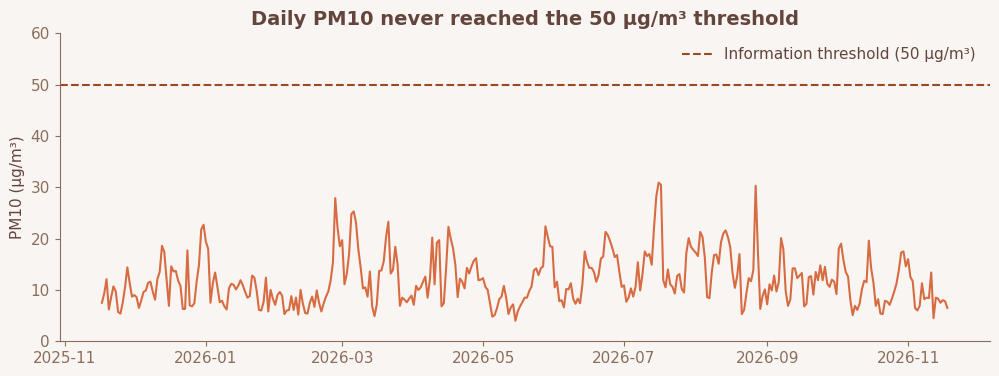

In [19]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_pm10["day"], daily_pm10["avg_pm10"], color=PALETTE["terracotta"], linewidth=1.5)
ax.axhline(50, color=PALETTE["brick"], linestyle="--", label="Information threshold (50 µg/m³)")
ax.set_title("Daily PM10 never reached the 50 µg/m³ threshold")
ax.set_ylabel("PM10 (µg/m³)")
ax.set_ylim(0, 60)
ax.legend(frameon=False)
plt.show()

## 2. Number of peak days

A peak day is a day when the average PM10 exceeds 50 µg/m³ (French information threshold).

In [16]:
run_query("""
    -- Query 2: number of peak days (daily average PM10 above 50 µg/m³)
    WITH daily AS (
        SELECT DATE(measured_at) AS day, AVG(pm10) AS avg_pm10
        FROM air_quality
        GROUP BY day
    )
    SELECT COUNT(*) AS total_days,
           COUNT(*) FILTER (WHERE avg_pm10 > 50) AS peak_days,
           COUNT(*) FILTER (WHERE avg_pm10 > 30) AS days_above_30,
           ROUND(MAX(avg_pm10)::numeric, 1) AS max_daily_pm10
    FROM daily;
""")

,total_days,peak_days,days_above_30,max_daily_pm10
0,367,0,3,30.9


**Observation:** no day exceeds 50 µg/m³ over the last 12 months (maximum: 30.9 µg/m³ on 2026-07-16).
Open-Meteo data come from the CAMS model, which works on ~10 km grid cells and smooths local peaks (roads, port).
As the subject recommends, I asked my supervisor which threshold to use for the alerts.

## 3. Average PM10 on strong wind days vs weak wind days

To test the mistral hypothesis, we join air quality and weather by day, then group the days into three wind classes based on the daily average wind speed.

In [17]:
wind_vs_pm10 = run_query("""
    -- Query 3: average PM10 by wind class (weak / moderate / strong)
    WITH daily_air AS (
        SELECT DATE(measured_at) AS day, AVG(pm10) AS avg_pm10
        FROM air_quality
        GROUP BY day
    ),
    daily_weather AS (
        SELECT DATE(measured_at) AS day, AVG(wind_speed) AS avg_wind
        FROM weather
        GROUP BY day
    )
    SELECT CASE
               WHEN w.avg_wind < 10 THEN '1. weak (< 10 km/h)'
               WHEN w.avg_wind < 20 THEN '2. moderate (10-20 km/h)'
               ELSE '3. strong (>= 20 km/h)'
           END AS wind_class,
           COUNT(*) AS nb_days,
           ROUND(AVG(a.avg_pm10)::numeric, 1) AS avg_pm10
    FROM daily_air AS a
    JOIN daily_weather AS w ON a.day = w.day
    GROUP BY wind_class
    ORDER BY wind_class;
""")
wind_vs_pm10

,wind_class,nb_days,avg_pm10
0,1. weak (< 10 km/h),141,15.1
1,2. moderate (10-20 km/h),150,10.5
2,3. strong (>= 20 km/h),76,8.7


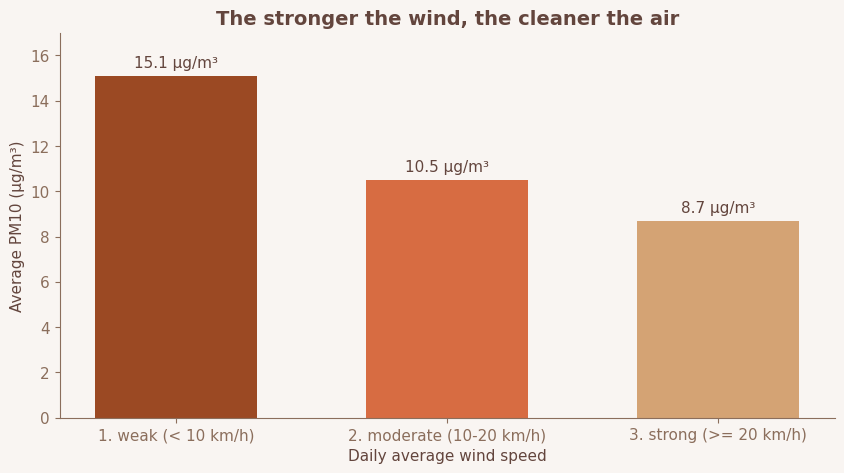

In [20]:
fig, ax = plt.subplots()
bars = ax.bar(wind_vs_pm10["wind_class"], wind_vs_pm10["avg_pm10"],
              color=list(COLORS.values()), width=0.6)
ax.bar_label(bars, fmt="%.1f µg/m³", padding=4)
ax.set_title("The stronger the wind, the cleaner the air")
ax.set_xlabel("Daily average wind speed")
ax.set_ylabel("Average PM10 (µg/m³)")
ax.set_ylim(0, 17)
plt.show()

## 4. Is it really the mistral?

The mistral is a strong wind blowing from the north-west (wind direction between 270° and 360°).
A day is labelled as a **mistral day** when the average wind is at least 20 km/h **and** the wind blows from the north-west for at least 12 hours.
We compare mistral days with other strong wind days and with calm days.

In [21]:
mistral = run_query("""
    -- Query 4: average PM10 on mistral days vs other strong wind days vs no strong wind
    WITH daily_air AS (
        SELECT DATE(measured_at) AS day, AVG(pm10) AS avg_pm10
        FROM air_quality
        GROUP BY day
    ),
    daily_weather AS (
        SELECT DATE(measured_at) AS day,
               AVG(wind_speed) AS avg_wind,
               COUNT(*) FILTER (WHERE wind_direction BETWEEN 270 AND 360) AS north_west_hours
        FROM weather
        GROUP BY day
    )
    SELECT CASE
               WHEN w.avg_wind >= 20 AND w.north_west_hours >= 12 THEN '1. mistral (strong NW wind)'
               WHEN w.avg_wind >= 20 THEN '2. other strong wind'
               ELSE '3. no strong wind'
           END AS day_type,
           COUNT(*) AS nb_days,
           ROUND(AVG(a.avg_pm10)::numeric, 1) AS avg_pm10
    FROM daily_air AS a
    JOIN daily_weather AS w ON a.day = w.day
    GROUP BY day_type
    ORDER BY day_type;
""")
mistral

,day_type,nb_days,avg_pm10
0,1. mistral (strong NW wind),54,7.6
1,2. other strong wind,22,11.3
2,3. no strong wind,291,12.7


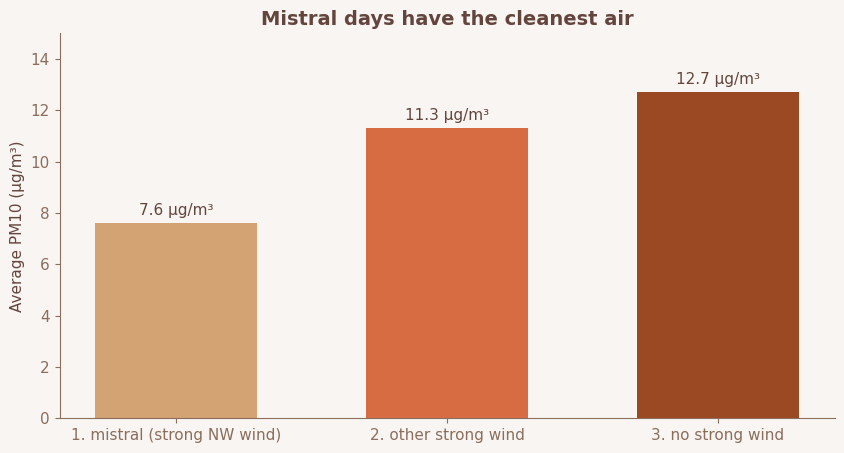

In [22]:
fig, ax = plt.subplots()
bars = ax.bar(mistral["day_type"], mistral["avg_pm10"],
              color=[PALETTE["camel"], PALETTE["terracotta"], PALETTE["brick"]], width=0.6)
ax.bar_label(bars, fmt="%.1f µg/m³", padding=4)
ax.set_ylim(0, 15)
ax.set_title("Mistral days have the cleanest air")
ax.set_ylabel("Average PM10 (µg/m³)")
plt.show()

## 5. PM10 and mistral days by month

Mistral days are not spread evenly over the year. To check whether the season, rather than the wind, explains the differences, we look at PM10 and the number of mistral days month by month.

In [25]:
monthly = run_query("""
    -- Query 5: average PM10 and number of mistral days per month
    WITH daily_air AS (
        SELECT DATE(measured_at) AS day, AVG(pm10) AS avg_pm10
        FROM air_quality
        GROUP BY day
    ),
    daily_weather AS (
        SELECT DATE(measured_at) AS day,
               AVG(wind_speed) AS avg_wind,
               COUNT(*) FILTER (WHERE wind_direction BETWEEN 270 AND 360) AS north_west_hours
        FROM weather
        GROUP BY day
    )
    SELECT EXTRACT(MONTH FROM a.day)::int AS month,
           COUNT(*) AS nb_days,
           ROUND(AVG(a.avg_pm10)::numeric, 1) AS avg_pm10,
           COUNT(*) FILTER (WHERE w.avg_wind >= 20 AND w.north_west_hours >= 12) AS mistral_days
    FROM daily_air AS a
    JOIN daily_weather AS w ON a.day = w.day
    GROUP BY month
    ORDER BY month;
""")
monthly

,month,nb_days,avg_pm10,mistral_days
0,1,31,10.0,7
1,2,28,9.6,9
2,3,31,13.7,9
3,4,30,13.3,3
4,5,31,10.4,5
5,6,30,12.9,3
6,7,31,14.8,4
7,8,31,14.7,1
8,9,30,11.7,3
9,10,31,11.0,4


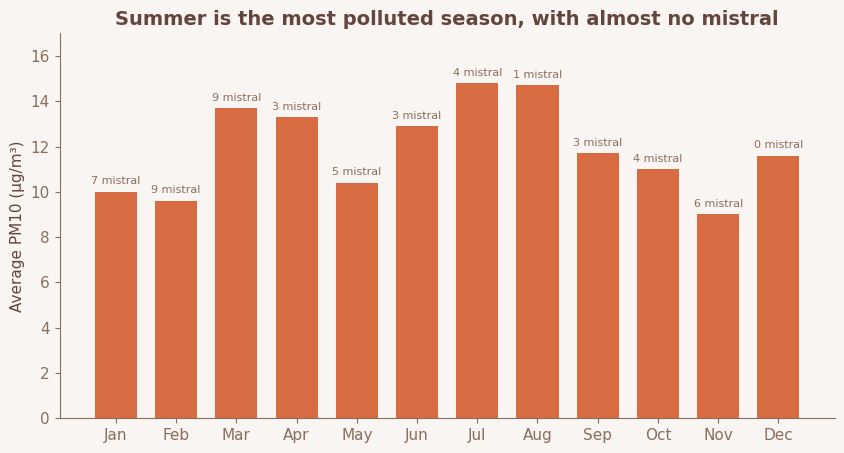

In [26]:
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots()
bars = ax.bar(monthly["month"], monthly["avg_pm10"], color=PALETTE["terracotta"], width=0.7)
ax.bar_label(bars, labels=[f"{n} mistral" for n in monthly["mistral_days"]],
             padding=4, fontsize=8, color=PALETTE["taupe"])
ax.set_xticks(range(1, 13), MONTH_NAMES)
ax.set_ylim(0, 17)
ax.set_title("Summer is the most polluted season, with almost no mistral")
ax.set_ylabel("Average PM10 (µg/m³)")
plt.show()

## Conclusion: does the mistral really lower air pollution?

**Yes.** On mistral days, average PM10 is 7.6 µg/m³, versus 12.7 µg/m³ on days without strong wind (about -40%).
It is not just "any wind": strong winds from other directions barely help (11.3 µg/m³).
The result holds when the thresholds of the mistral definition change (sensitivity test).

**Caveat:** the season also matters. Summer is the most polluted season and has almost no mistral, so part of the gap comes from the season. March, however, stays polluted despite 9 mistral days: the mistral helps, but it does not explain everything.